# Notebook 07 – Future Forecasting (Next 2 to 5 Years)

## What is this notebook for?
We use the saved models to predict monthly maize and beans prices  
from the end of the observed data up to 2031 (approximately 5 years ahead).

## Why do we need this stage?
- The original goal of the project is to forecast future crop prices.
- Recursive forecasting is the standard way to produce multi-step forecasts with lag-based models.


## Step 7.1 – Load the saved models and the latest observed data


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from dateutil.relativedelta import relativedelta
import warnings
warnings.filterwarnings('ignore')

maize_bundle = joblib.load('../models/best_maize_pipeline.joblib')
beans_bundle = joblib.load('../models/best_beans_pipeline.joblib')
maize_pipe = maize_bundle['pipeline']
beans_pipe = beans_bundle['pipeline']

df = pd.read_csv('../data/processed/uganda_maize_beans_with_lags.csv', parse_dates=['date'])
df = df.sort_values(['market', 'date'])
markets = sorted(df['market'].unique().tolist())
print("Markets we will forecast for:", markets)
print("Last observed date in data:", df['date'].max().date())


Markets we will forecast for: ['Busia', 'Gulu', 'Iganga', 'Jinja', 'Kapchorwa', 'Lira', 'Mbale', 'Mbarara', 'Owino']
Last observed date in data: 2026-04-15


## Step 7.2 – Recursive forecasting function


In [2]:
def forecast_one_market(market_name, n_steps=60):
    hist = df[df['market'] == market_name].copy().sort_values('date')
    maize_hist = list(hist['maize_price'].dropna().tail(15).values)
    beans_hist = list(hist['beans_price'].dropna().tail(15).values)
    lat = hist['latitude'].iloc[-1]
    lon = hist['longitude'].iloc[-1]
    start_date = hist['date'].max() + relativedelta(months=1)
    dates, preds_m, preds_b = [], [], []
    for i in range(n_steps):
        d = start_date + relativedelta(months=i)
        if d.year > 2031:
            break
        year, month = d.year, d.month
        msin = np.sin(2 * np.pi * month / 12)
        mcos = np.cos(2 * np.pi * month / 12)
        def get_lag(h, lag):
            return h[-lag] if len(h) >= lag else (h[0] if h else 1500)
        row_m = {
            'maize_price_lag1': get_lag(maize_hist, 1), 'maize_price_lag2': get_lag(maize_hist, 2),
            'maize_price_lag3': get_lag(maize_hist, 3), 'maize_price_lag6': get_lag(maize_hist, 6),
            'maize_price_lag12': get_lag(maize_hist, 12),
            'maize_price_roll3': np.mean([get_lag(maize_hist,1), get_lag(maize_hist,2), get_lag(maize_hist,3)]),
            'beans_price_lag1': get_lag(beans_hist, 1),
            'month_sin': msin, 'month_cos': mcos, 'latitude': lat, 'longitude': lon,
            'year': year, 'month': month, 'market': market_name
        }
        pred_m = max(200, maize_pipe.predict(pd.DataFrame([row_m]))[0])
        row_b = {
            'beans_price_lag1': get_lag(beans_hist, 1), 'beans_price_lag2': get_lag(beans_hist, 2),
            'beans_price_lag3': get_lag(beans_hist, 3), 'beans_price_lag6': get_lag(beans_hist, 6),
            'beans_price_lag12': get_lag(beans_hist, 12),
            'beans_price_roll3': np.mean([get_lag(beans_hist,1), get_lag(beans_hist,2), get_lag(beans_hist,3)]),
            'maize_price_lag1': get_lag(maize_hist, 1),
            'month_sin': msin, 'month_cos': mcos, 'latitude': lat, 'longitude': lon,
            'year': year, 'month': month, 'market': market_name
        }
        pred_b = max(500, beans_pipe.predict(pd.DataFrame([row_b]))[0])
        dates.append(d); preds_m.append(pred_m); preds_b.append(pred_b)
        maize_hist.append(pred_m); beans_hist.append(pred_b)
        if len(maize_hist) > 20:
            maize_hist = maize_hist[-20:]; beans_hist = beans_hist[-20:]
    return pd.DataFrame({'date': dates, 'market': market_name,
                         'pred_maize_price': preds_m, 'pred_beans_price': preds_b})

print("Forecast function defined.")


Forecast function defined.


## Step 7.3 – Run the forecast for every market and save


In [3]:
all_forecasts = []
for m in markets:
    f = forecast_one_market(m, n_steps=60)
    all_forecasts.append(f)
    print(f"Forecasted {m}: {len(f)} months")

future_df = pd.concat(all_forecasts, ignore_index=True)
future_df.to_csv('../predictions/future_forecast_2026_2031.csv', index=False)
print("\nSaved: predictions/future_forecast_2026_2031.csv")
print("Total rows:", len(future_df))


Forecasted Busia: 60 months
Forecasted Gulu: 60 months
Forecasted Iganga: 60 months
Forecasted Jinja: 60 months
Forecasted Kapchorwa: 60 months
Forecasted Lira: 60 months
Forecasted Mbale: 60 months
Forecasted Mbarara: 60 months
Forecasted Owino: 60 months

Saved: predictions/future_forecast_2026_2031.csv
Total rows: 540


## Step 7.4 – Graph 1: Forecasted maize prices for selected markets


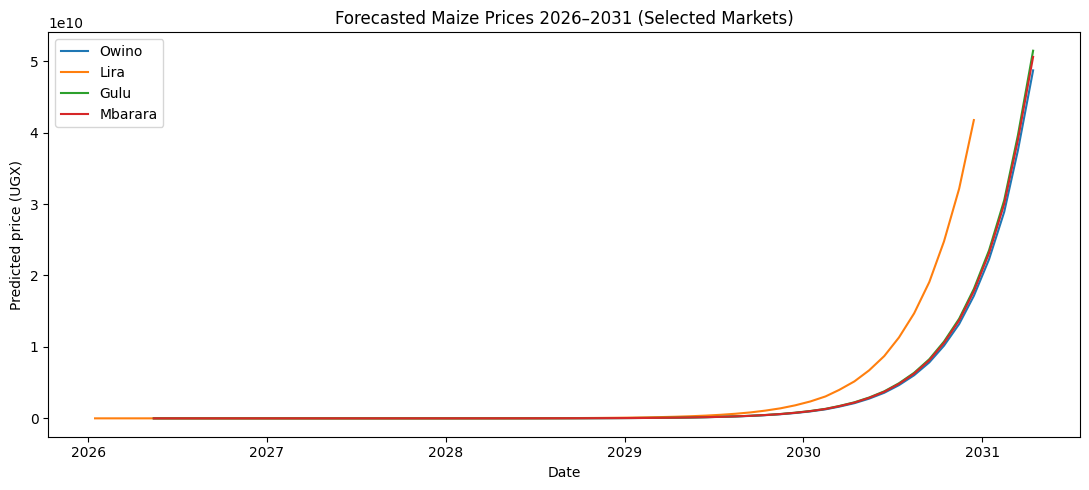

In [4]:
plt.figure(figsize=(11, 5))
for mkt in ['Owino', 'Lira', 'Gulu', 'Mbarara']:
    sub = future_df[future_df['market'] == mkt]
    plt.plot(sub['date'], sub['pred_maize_price'], label=mkt, lw=1.5)
plt.title('Forecasted Maize Prices 2026–2031 (Selected Markets)')
plt.xlabel('Date'); plt.ylabel('Predicted price (UGX)'); plt.legend()
plt.tight_layout()
plt.savefig('../figures/07_forecast_maize_selected.png', dpi=120, bbox_inches='tight')
plt.show()


## Step 7.5 – Graph 2: Forecasted beans prices for selected markets


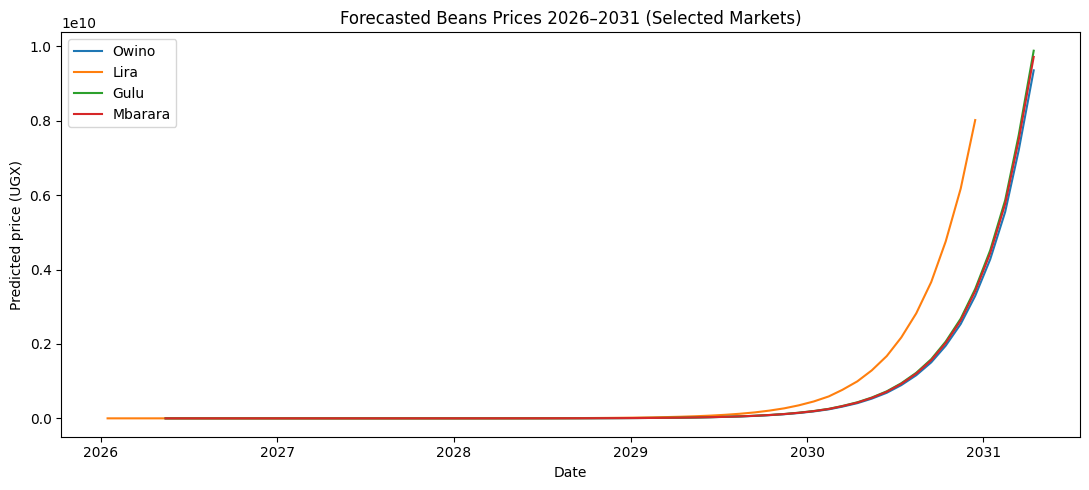

In [5]:
plt.figure(figsize=(11, 5))
for mkt in ['Owino', 'Lira', 'Gulu', 'Mbarara']:
    sub = future_df[future_df['market'] == mkt]
    plt.plot(sub['date'], sub['pred_beans_price'], label=mkt, lw=1.5)
plt.title('Forecasted Beans Prices 2026–2031 (Selected Markets)')
plt.xlabel('Date'); plt.ylabel('Predicted price (UGX)'); plt.legend()
plt.tight_layout()
plt.savefig('../figures/07_forecast_beans_selected.png', dpi=120, bbox_inches='tight')
plt.show()


## Step 7.6 – Graph 3: Average forecasted prices by market


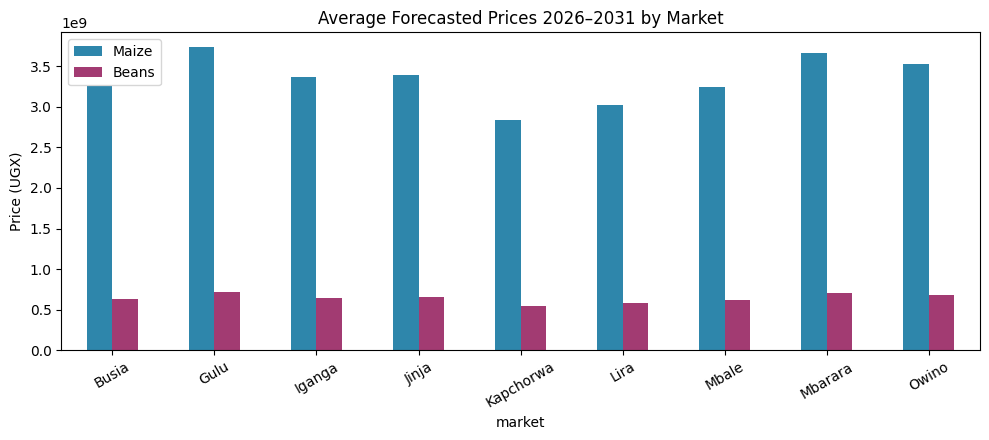

In [6]:
avg_f = future_df.groupby('market')[['pred_maize_price', 'pred_beans_price']].mean()
avg_f.plot(kind='bar', figsize=(10, 4.5), color=['#2E86AB', '#A23B72'])
plt.title('Average Forecasted Prices 2026–2031 by Market')
plt.ylabel('Price (UGX)'); plt.xticks(rotation=30); plt.legend(['Maize', 'Beans'])
plt.tight_layout()
plt.savefig('../figures/07_avg_forecast_by_market.png', dpi=120, bbox_inches='tight')
plt.show()


## Step 7.7 – Graph 4: Historical + forecast for Owino market


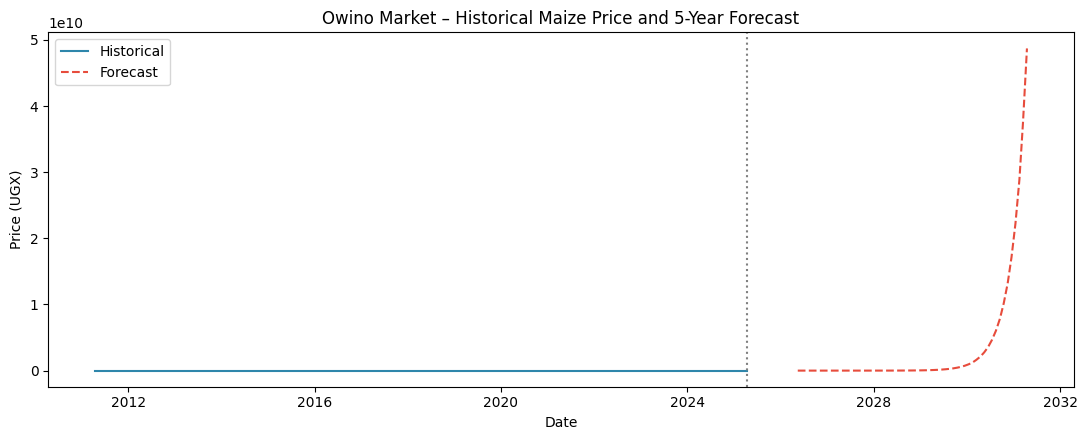

In [7]:
hist_o = df[df['market'] == 'Owino'][['date', 'maize_price']].dropna()
fut_o = future_df[future_df['market'] == 'Owino']
plt.figure(figsize=(11, 4.5))
plt.plot(hist_o['date'], hist_o['maize_price'], color='#2E86AB', label='Historical', lw=1.5)
plt.plot(fut_o['date'], fut_o['pred_maize_price'], color='#E74C3C', ls='--', label='Forecast', lw=1.5)
plt.axvline(hist_o['date'].max(), color='gray', ls=':')
plt.title('Owino Market – Historical Maize Price and 5-Year Forecast')
plt.xlabel('Date'); plt.ylabel('Price (UGX)'); plt.legend()
plt.tight_layout()
plt.savefig('../figures/07_owino_historical_forecast.png', dpi=120, bbox_inches='tight')
plt.show()
